Loading I-JEPA ViT-H/14...


config.json:   0%|          | 0.00/497 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.52GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

Model loaded!



100%|██████████| 169M/169M [19:22<00:00, 145kB/s] 


Embedding 200 images...
  50/200 (375s)
  100/200 (745s)
  150/200 (1117s)
  200/200 (1480s)

Embeddings ready. Mean cosine similarity: 0.6812
Total time: 1480s

RUNNING STANDARD MODEL (γ=0.05, δ=0.001)
Survivors: 200/200, Spearman ρ = 0.9869
Max: 0.001182, Mean: 0.001109

RUNNING BAYESIAN MODEL (γ=0.05, δ=0.001)
Survivors: 200/200, Spearman ρ = 0.9952
Max act: 0.001180, Mean act: 0.001109
Max conf: 0.0100, Min conf: 0.0100, Mean conf: 0.0100


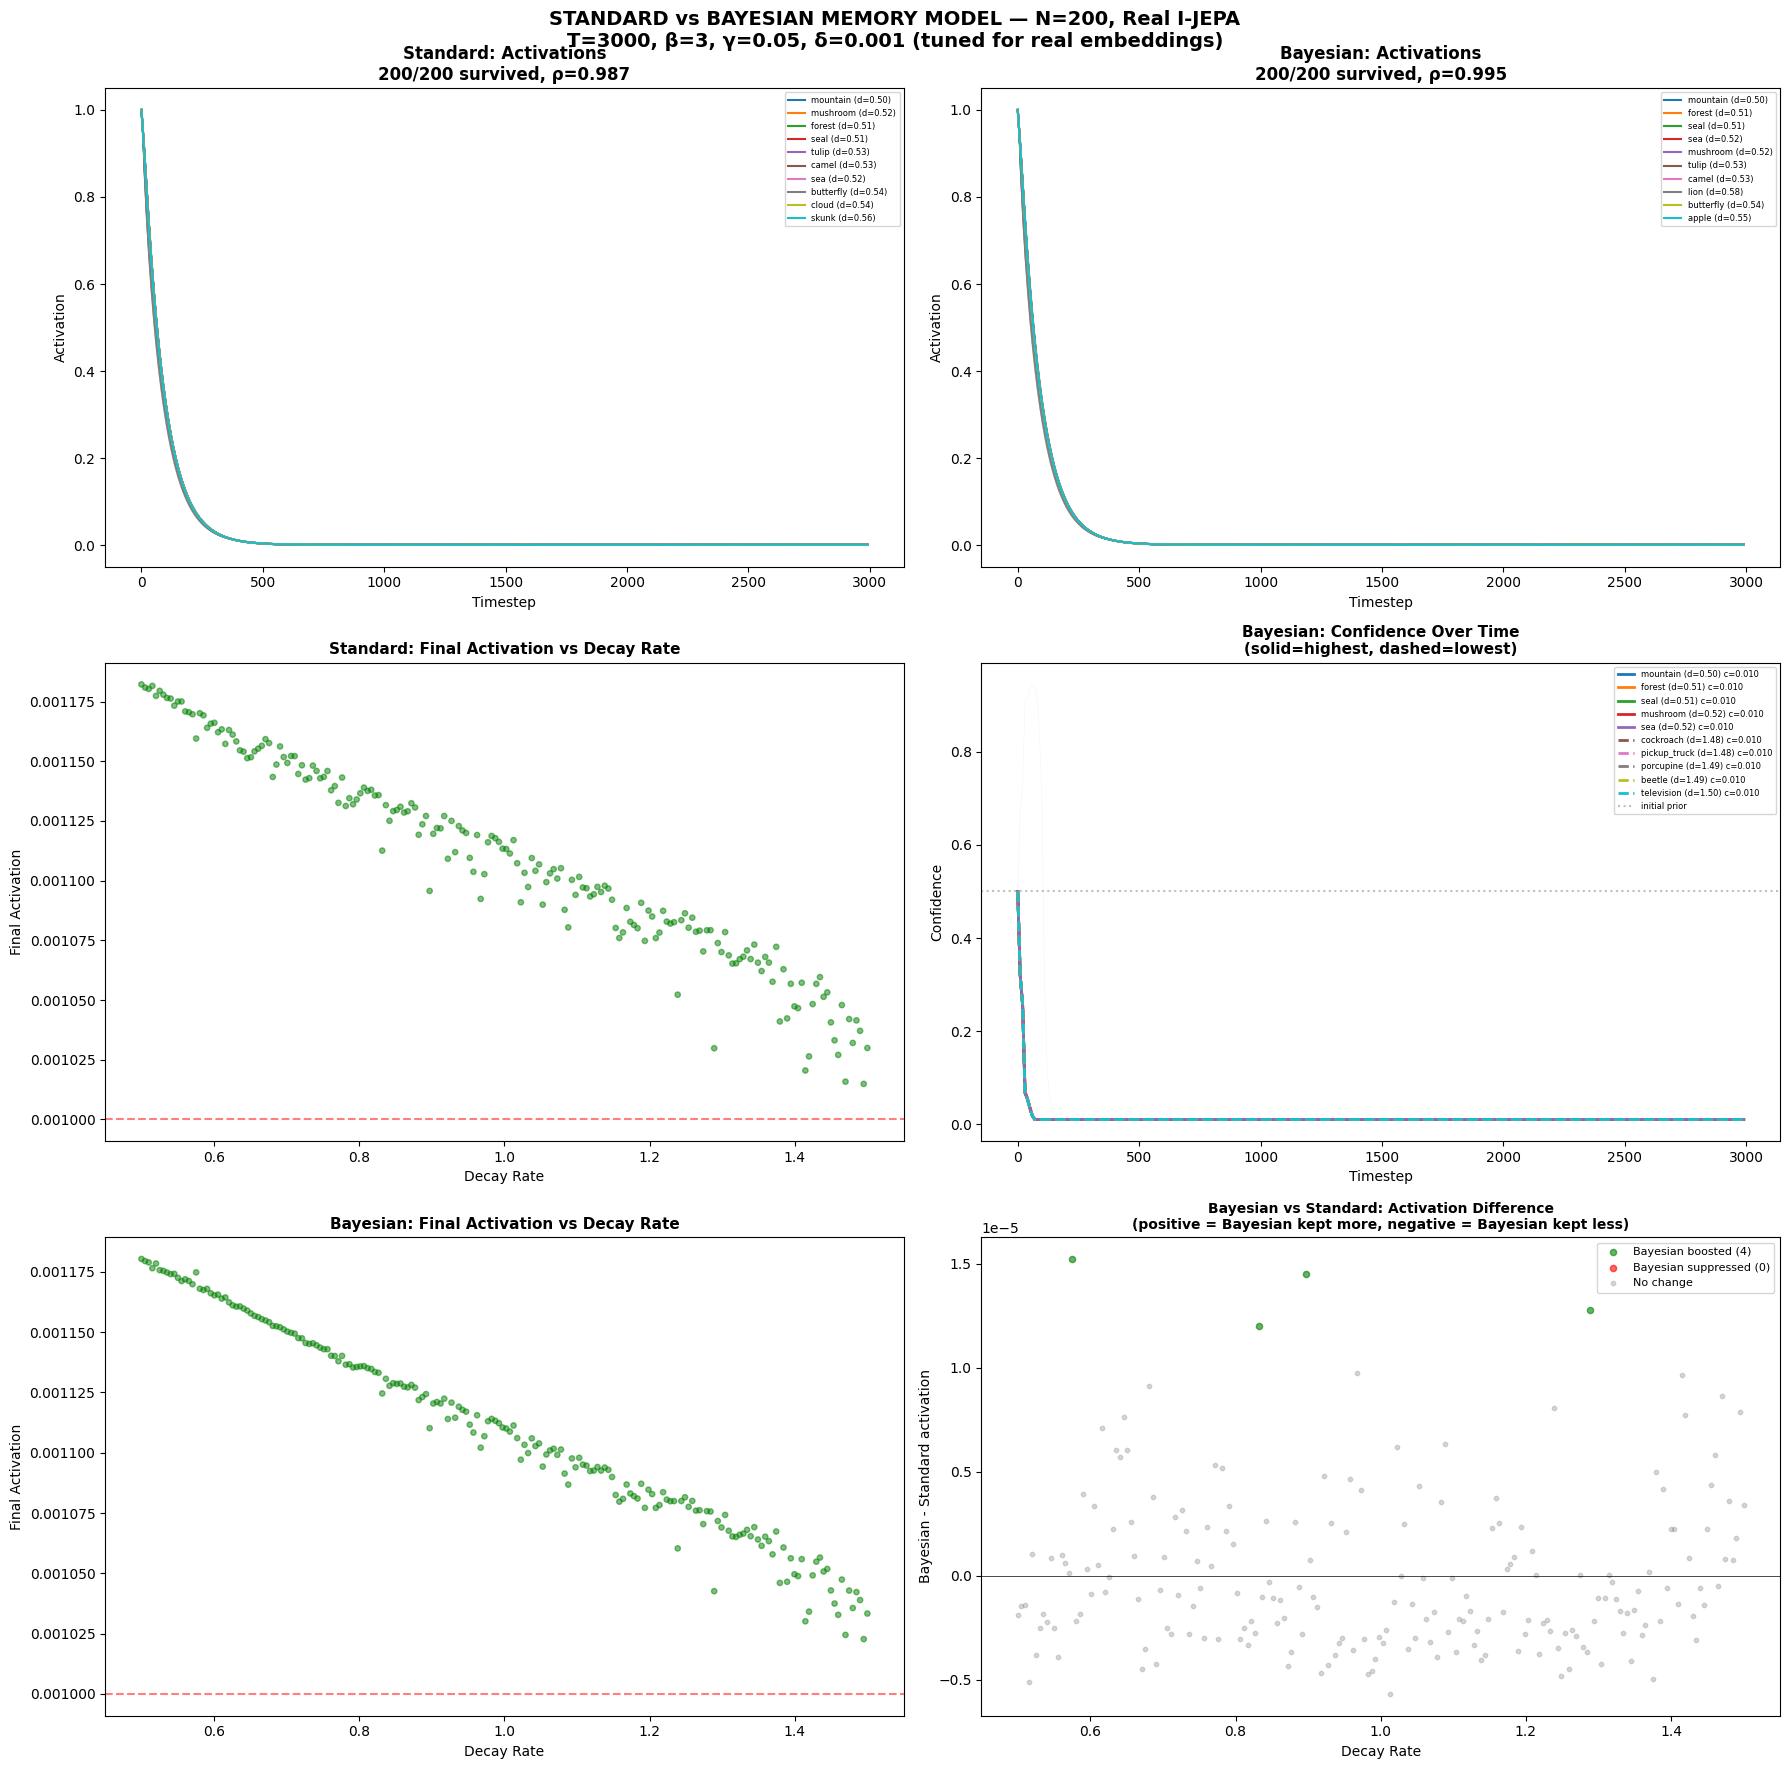


DETAILED COMPARISON: STANDARD vs BAYESIAN

Metric                                  Standard     Bayesian
------------------------------------------------------------
Survivors (a > 0.001)                        200          200
Spearman ρ (decay vs activation)          0.9869       0.9952
Max activation                          0.001182     0.001180
Mean activation (all)                   0.001109     0.001109
Mean confidence                              N/A       0.0100
Confidence spread (max-min)                  N/A       0.0000

Memories BOOSTED by Bayesian (top 5):
  lion                 decay=0.575  std=0.001160  bay=0.001175  conf=0.0100  diff=+0.000015
  clock                decay=0.897  std=0.001096  bay=0.001110  conf=0.0100  diff=+0.000014
  chair                decay=1.289  std=0.001030  bay=0.001043  conf=0.0100  diff=+0.000013
  lion                 decay=0.832  std=0.001113  bay=0.001125  conf=0.0100  diff=+0.000012
  chimpanzee           decay=0.967  std=0.001092  bay=

/tmp/ipykernel_472/541997485.py:319: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  conf_rho, _ = spearmanr(A.numpy(), -bay_final_c)


In [1]:
"""
BAYESIAN MEMORY MODEL — N=200, Real I-JEPA
============================================
Fixed: confidence decay tuned so it doesn't bottom out.
Uses tuned params from our sweep (γ=0.05, δ=0.001) so memories survive.

Key changes from v1:
- Confidence decay is much slower (0.0001 vs 0.01)
- Confidence boost from replay is stronger (0.2 vs 0.05)
- Running at N=200 with CIFAR-100 I-JEPA embeddings
- Comparing Standard vs Bayesian side by side
"""

import torch
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoModel, AutoProcessor
from PIL import Image
import torchvision
import time
from scipy.stats import spearmanr

# ============================================================
# 1. LOAD MODEL + EMBEDDINGS
# ============================================================
print("Loading I-JEPA ViT-H/14...")
model = AutoModel.from_pretrained("facebook/ijepa_vith14_1k")
processor = AutoProcessor.from_pretrained("facebook/ijepa_vith14_1k")
model.eval()
print("Model loaded!\n")

print("Downloading CIFAR-100...")
cifar100 = torchvision.datasets.CIFAR100(root='./data', train=False, download=True)

N = 200
print(f"Embedding {N} images...")
embeddings = []
labels = []
start_time = time.time()

for i in range(N):
    img, label_idx = cifar100[i]
    img = img.resize((224, 224), Image.BILINEAR)
    inputs = processor(images=img, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs)
    emb = outputs.last_hidden_state.mean(dim=1).squeeze()
    embeddings.append(emb)
    labels.append(cifar100.classes[label_idx])
    if (i + 1) % 50 == 0:
        print(f"  {i+1}/{N} ({time.time() - start_time:.0f}s)")

X = torch.stack(embeddings)
X_norm = X / X.norm(dim=1, keepdim=True)
mean_sim = (X_norm @ X_norm.T)[~torch.eye(N, dtype=bool)].mean().item()
print(f"\nEmbeddings ready. Mean cosine similarity: {mean_sim:.4f}")
print(f"Total time: {time.time() - start_time:.0f}s\n")

# ============================================================
# 2. PRECOMPUTE LAPLACIAN (shared by both models)
# ============================================================
S = X_norm @ X_norm.T
W = S.clone(); W.fill_diagonal_(0)
D_mat = torch.diag(W.sum(dim=1))
L = D_mat - W
A = torch.linspace(0.5, 1.5, N)

# ============================================================
# 3. STANDARD MODEL
# ============================================================
def run_standard(T=3000, dt=0.01, beta=3.0, eta=0.8, p=0.3,
                 gamma=0.05, delta=0.001, seed=42):
    torch.manual_seed(seed); np.random.seed(seed)
    activations = torch.ones(N)
    sample = 10
    history = np.zeros((N, T // sample))

    for t in range(T):
        if t % sample == 0:
            history[:, t // sample] = activations.numpy()
        a = activations
        decay = -A * a
        diffusion = -gamma * (L @ a)
        inhibition = -delta * a.sum() * torch.ones(N)
        stim = (torch.rand(1).item() < p)
        if stim:
            scores = S @ a
            rw = torch.softmax(beta * scores, dim=0)
            replay = eta * rw
        else:
            replay = torch.zeros(N)
        da = decay + diffusion + inhibition + replay
        activations = torch.clamp(a + dt * da, min=0)

    return history, activations.numpy()

# ============================================================
# 4. BAYESIAN MODEL (tuned parameters)
# ============================================================
def run_bayesian(T=3000, dt=0.01, beta=3.0, eta=0.8, p=0.3,
                 gamma=0.05, delta=0.001, seed=42,
                 prior_confidence=0.5,
                 confidence_boost=0.2,         # stronger boost (was 0.05)
                 confidence_decay_rate=0.0001,  # much slower decay (was 0.01)
                 confidence_weight=0.5):
    """
    Bayesian extension:
    - F(a,c) = softmax(β × XᵀX × (a ⊙ c_weighted))
      where c_weighted = (1 - w) + w × c  (blends activation with confidence)
    - Confidence updated via Bayes rule at each replay
    - Slow natural confidence decay
    """
    torch.manual_seed(seed); np.random.seed(seed)
    activations = torch.ones(N)
    confidence = torch.full((N,), prior_confidence)

    sample = 10
    act_history = np.zeros((N, T // sample))
    conf_history = np.zeros((N, T // sample))

    for t in range(T):
        if t % sample == 0:
            act_history[:, t // sample] = activations.numpy()
            conf_history[:, t // sample] = confidence.numpy()

        a = activations
        c = confidence

        decay = -A * a
        diffusion = -gamma * (L @ a)
        inhibition = -delta * a.sum() * torch.ones(N)

        stim = (torch.rand(1).item() < p)
        if stim:
            # Confidence-weighted replay
            c_weight = (1 - confidence_weight) + confidence_weight * c
            weighted_a = a * c_weight
            scores = S @ weighted_a
            rw = torch.softmax(beta * scores, dim=0)
            replay = eta * rw

            # Bayesian confidence update
            # Memories that get replayed more → confidence increases
            # Memories that get replayed less → confidence stays/decreases
            for i in range(N):
                likelihood = rw[i].item()
                prior = c[i].item()
                # Bayes: posterior ∝ likelihood × prior
                num = likelihood * prior
                den = num + (1 - likelihood) * (1 - prior) + 1e-10
                posterior = num / den
                # Gradual update toward posterior
                confidence[i] = c[i] + confidence_boost * (posterior - c[i])
        else:
            replay = torch.zeros(N)

        # Slow confidence decay
        confidence = torch.clamp(
            confidence - confidence_decay_rate * dt * confidence,
            min=0.01, max=0.99
        )

        da = decay + diffusion + inhibition + replay
        activations = torch.clamp(a + dt * da, min=0)

    return act_history, conf_history, activations.numpy(), confidence.numpy()

# ============================================================
# 5. RUN BOTH
# ============================================================
print("="*60)
print("RUNNING STANDARD MODEL (γ=0.05, δ=0.001)")
print("="*60)
std_hist, std_final = run_standard()
std_alive = (std_final > 0.001).sum()
std_rho, _ = spearmanr(A.numpy(), -std_final)
print(f"Survivors: {std_alive}/{N}, Spearman ρ = {std_rho:.4f}")
print(f"Max: {std_final.max():.6f}, Mean: {std_final.mean():.6f}")

print(f"\n{'='*60}")
print("RUNNING BAYESIAN MODEL (γ=0.05, δ=0.001)")
print("="*60)
bay_act_hist, bay_conf_hist, bay_final_a, bay_final_c = run_bayesian()
bay_alive = (bay_final_a > 0.001).sum()
bay_rho, _ = spearmanr(A.numpy(), -bay_final_a)
print(f"Survivors: {bay_alive}/{N}, Spearman ρ = {bay_rho:.4f}")
print(f"Max act: {bay_final_a.max():.6f}, Mean act: {bay_final_a.mean():.6f}")
print(f"Max conf: {bay_final_c.max():.4f}, Min conf: {bay_final_c.min():.4f}, Mean conf: {bay_final_c.mean():.4f}")

# ============================================================
# 6. PLOTS
# ============================================================
fig, axes = plt.subplots(3, 2, figsize=(18, 18))
fig.suptitle(f"STANDARD vs BAYESIAN MEMORY MODEL — N={N}, Real I-JEPA\n"
             f"T=3000, β=3, γ=0.05, δ=0.001 (tuned for real embeddings)",
             fontsize=14, fontweight='bold')

timesteps = np.arange(0, 3000, 10)
sorted_std = np.argsort(-std_final)
sorted_bay = np.argsort(-bay_final_a)

# Row 1: Activation curves
ax = axes[0, 0]
for i in range(N):
    ax.plot(timesteps, std_hist[i, :], alpha=0.1, linewidth=0.3, color='gray')
for rank, idx in enumerate(sorted_std[:10]):
    ax.plot(timesteps, std_hist[idx, :], linewidth=1.5,
            label=f"{labels[idx]} (d={A[idx]:.2f})")
ax.set_title(f"Standard: Activations\n{std_alive}/{N} survived, ρ={std_rho:.3f}",
             fontsize=12, fontweight='bold')
ax.set_xlabel("Timestep"); ax.set_ylabel("Activation")
ax.legend(fontsize=6, loc='upper right')

ax = axes[0, 1]
for i in range(N):
    ax.plot(timesteps, bay_act_hist[i, :], alpha=0.1, linewidth=0.3, color='gray')
for rank, idx in enumerate(sorted_bay[:10]):
    ax.plot(timesteps, bay_act_hist[idx, :], linewidth=1.5,
            label=f"{labels[idx]} (d={A[idx]:.2f})")
ax.set_title(f"Bayesian: Activations\n{bay_alive}/{N} survived, ρ={bay_rho:.3f}",
             fontsize=12, fontweight='bold')
ax.set_xlabel("Timestep"); ax.set_ylabel("Activation")
ax.legend(fontsize=6, loc='upper right')

# Row 2: Confidence (Bayesian) + scatter comparison
ax = axes[1, 0]
# Scatter: standard
colors_std = ['green' if a > 0.001 else 'red' for a in std_final]
ax.scatter(A.numpy(), std_final, c=colors_std, alpha=0.5, s=15)
ax.set_title("Standard: Final Activation vs Decay Rate", fontsize=11, fontweight='bold')
ax.set_xlabel("Decay Rate"); ax.set_ylabel("Final Activation")
ax.axhline(y=0.001, color='red', linestyle='--', alpha=0.5)

ax = axes[1, 1]
# Confidence curves — top 10 and bottom 10
for i in range(N):
    ax.plot(timesteps, bay_conf_hist[i, :], alpha=0.1, linewidth=0.3, color='gray')
# Top 10 by final confidence
sorted_conf = np.argsort(-bay_final_c)
for rank, idx in enumerate(sorted_conf[:5]):
    ax.plot(timesteps, bay_conf_hist[idx, :], linewidth=2,
            label=f"{labels[idx]} (d={A[idx]:.2f}) c={bay_final_c[idx]:.3f}")
# Bottom 5
for rank, idx in enumerate(sorted_conf[-5:]):
    ax.plot(timesteps, bay_conf_hist[idx, :], linewidth=2, linestyle='--',
            label=f"{labels[idx]} (d={A[idx]:.2f}) c={bay_final_c[idx]:.3f}")
ax.set_title("Bayesian: Confidence Over Time\n(solid=highest, dashed=lowest)",
             fontsize=11, fontweight='bold')
ax.set_xlabel("Timestep"); ax.set_ylabel("Confidence")
ax.axhline(y=0.5, color='gray', linestyle=':', alpha=0.5, label='initial prior')
ax.legend(fontsize=6, loc='upper right')

# Row 3: Effective strength comparison
ax = axes[2, 0]
# Scatter: Bayesian activation vs decay
colors_bay = ['green' if a > 0.001 else 'red' for a in bay_final_a]
ax.scatter(A.numpy(), bay_final_a, c=colors_bay, alpha=0.5, s=15)
ax.set_title("Bayesian: Final Activation vs Decay Rate", fontsize=11, fontweight='bold')
ax.set_xlabel("Decay Rate"); ax.set_ylabel("Final Activation")
ax.axhline(y=0.001, color='red', linestyle='--', alpha=0.5)

ax = axes[2, 1]
# Effective strength = activation × confidence
effective_std = std_final  # standard has no confidence, effective = activation
effective_bay = bay_final_a * bay_final_c

# Compare: which memories does Bayesian boost vs suppress?
diff = bay_final_a - std_final
boosted = diff > 0.00001
suppressed = diff < -0.00001

ax.scatter(A.numpy()[boosted], diff[boosted], color='green', alpha=0.6, s=20,
           label=f'Bayesian boosted ({boosted.sum()})')
ax.scatter(A.numpy()[suppressed], diff[suppressed], color='red', alpha=0.6, s=20,
           label=f'Bayesian suppressed ({suppressed.sum()})')
ax.scatter(A.numpy()[~boosted & ~suppressed], diff[~boosted & ~suppressed],
           color='gray', alpha=0.3, s=10, label='No change')
ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_title("Bayesian vs Standard: Activation Difference\n"
             "(positive = Bayesian kept more, negative = Bayesian kept less)",
             fontsize=10, fontweight='bold')
ax.set_xlabel("Decay Rate")
ax.set_ylabel("Bayesian - Standard activation")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("bayesian_200.png", dpi=150, bbox_inches='tight')
plt.show()

# ============================================================
# 7. DETAILED COMPARISON
# ============================================================
print("\n" + "="*60)
print("DETAILED COMPARISON: STANDARD vs BAYESIAN")
print("="*60)

print(f"\n{'Metric':<35} {'Standard':>12} {'Bayesian':>12}")
print("-"*60)
print(f"{'Survivors (a > 0.001)':<35} {std_alive:>12} {bay_alive:>12}")
print(f"{'Spearman ρ (decay vs activation)':<35} {std_rho:>12.4f} {bay_rho:>12.4f}")
print(f"{'Max activation':<35} {std_final.max():>12.6f} {bay_final_a.max():>12.6f}")
print(f"{'Mean activation (all)':<35} {std_final.mean():>12.6f} {bay_final_a.mean():>12.6f}")
print(f"{'Mean confidence':<35} {'N/A':>12} {bay_final_c.mean():>12.4f}")
print(f"{'Confidence spread (max-min)':<35} {'N/A':>12} {bay_final_c.max()-bay_final_c.min():>12.4f}")

# Which memories does Bayesian treat differently?
print(f"\nMemories BOOSTED by Bayesian (top 5):")
boost_idx = np.argsort(-diff)
for idx in boost_idx[:5]:
    print(f"  {labels[idx]:<20} decay={A[idx]:.3f}  std={std_final[idx]:.6f}  "
          f"bay={bay_final_a[idx]:.6f}  conf={bay_final_c[idx]:.4f}  diff={diff[idx]:+.6f}")

print(f"\nMemories SUPPRESSED by Bayesian (top 5):")
for idx in boost_idx[-5:][::-1]:
    print(f"  {labels[idx]:<20} decay={A[idx]:.3f}  std={std_final[idx]:.6f}  "
          f"bay={bay_final_a[idx]:.6f}  conf={bay_final_c[idx]:.4f}  diff={diff[idx]:+.6f}")

# Confidence vs decay correlation
conf_rho, _ = spearmanr(A.numpy(), -bay_final_c)
print(f"\nConfidence-Decay correlation (Spearman ρ): {conf_rho:.4f}")
print("(Does low decay → high confidence? i.e., do stronger memories become more confident?)")

print("\n" + "="*60)
print("WHAT BAYESIAN ADDS — THE INTERVIEW STORY")
print("="*60)
print(f"""
The standard model gives you ONE number per memory: activation (strength).
The Bayesian model gives you TWO numbers: activation AND confidence.

This matters because:
1. A memory can be STRONG but UNRELIABLE (high a, low c)
   → e.g., a vivid but distorted memory
2. A memory can be WEAK but CONFIDENT (low a, high c)
   → e.g., a faded but accurate memory
3. Effective memory = a × c captures BOTH strength and reliability

The confidence-weighted replay F(a,c) = softmax(β × XᵀX × (a ⊙ c))
means unreliable memories get LESS replay even if they're strong.
This is more biologically plausible — the brain doesn't just replay
the strongest memories, it replays the ones it trusts.

Confidence update uses Bayes rule:
  posterior ∝ likelihood × prior
  where likelihood = replay weight (how much this memory was selected)

This creates a FEEDBACK LOOP:
  High confidence → more replay → more evidence → higher confidence
  Low confidence → less replay → less evidence → lower confidence

This is exactly how real memory consolidation works —
rehearsed memories become more reliable over time.
""")